M303 - Visualización de datos
Módulo III - Python para la inteligencia artificial

Tema 3: Visualización de datos (Matplotlib, Seaborn)

Contenido:

Análisis Individual para Características Continuas
Análisis Individual para Características Discretas
Selección de la Respuesta
Discretización
Cuantización
Análisis Cruzado de las Características Contra la Respuesta

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [2]:
titanic = pandas.read_csv("../conjuntos/titanic.csv")

titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Cascada de relevancia en la información del conjunto de datos que es analizable
titanic[["Survived", "Sex", "Pclass", "Fare", "Cabin", "Embarked", "Age", "SibSp", "Parch"]].head()

,Survived,Sex,Pclass,Fare,Cabin,Embarked,Age,SibSp,Parch
0,0,male,3,7.2500,NaN,S,22.0,1,0
1,1,female,1,71.2833,C85,C,38.0,1,0
2,1,female,3,7.9250,NaN,S,26.0,0,0
3,1,female,1,53.1000,C123,S,35.0,1,0
4,0,male,3,8.0500,NaN,S,35.0,0,0


In [7]:
# Nataturaleza | Codificación | Tipo
# Cuantitativa/Cualitativa | Numérica/Categórica | Continuo/Discreta

c1 = titanic["Survived"].map({
    0: "no",
    1: "yes"
}) # Cualitativa | Numérica | Discreta {0,1} -> Clases {no, yes}
c2 = titanic["Sex"] # Cualitativo | Categórico | Discreto {male, female}
c3 = titanic["Pclass"].map({
    1: "1st",
    2: "2nd",
    3: "3rd",
}) # Cualitativo | Numérico | Discreto {1, 2, 3} -> Clases {1st, 2nd, 3rd}
c4 = titanic["Fare"] # Cuantitativa | Numérica | Continua
c5 = (~(titanic["Cabin"].isna())).map({
    True: "yes",
    False: "no"
}) # Cualitativa | Categórica | Discreta {NaN, CXX, ???} -> { True, False } -> { yes, no }
c6 = titanic["Embarked"].map({
    "S": "southampton",
    "C": "cherbug",
    "Q": "queenstown",
}) # Cualitativa | Categórica | Discreta {S, C, Q} -> {southampton, cherbug, queenstown}
c7 = titanic["Age"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta 
#                                               (discreto ordenado con muchas clases)
c8 = titanic["SibSp"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta 
c9 = titanic["Parch"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta

In [6]:
titanic["Survived"].describe()

count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64

1. Análisis Individual para Características Continuas

In [8]:
pandas.DataFrame([c4, c7, c8, c9]).T.describe() 

# Solo creer la densidad muestra un solo c´
# y si la distribución es normal

,Fare,Age,SibSp,Parch
count,891.000000,714.000000,891.000000,891.000000
mean,32.204208,29.699118,0.523008,0.381594
std,49.693429,14.526497,1.102743,0.806057
min,0.000000,0.420000,0.000000,0.000000
25%,7.910400,20.125000,0.000000,0.000000
50%,14.454200,28.000000,0.000000,0.000000
75%,31.000000,38.000000,1.000000,0.000000
max,512.329200,80.000000,8.000000,6.000000


(0.0, 600.0)

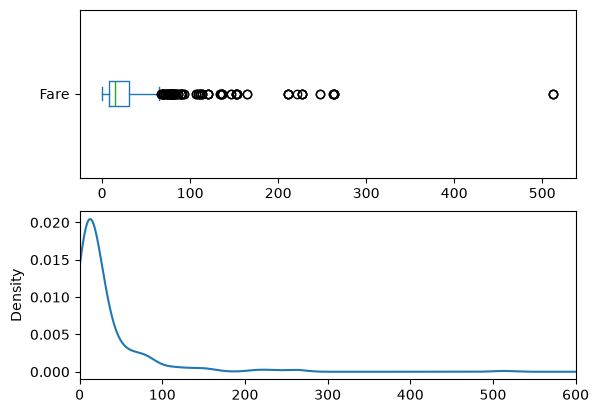

In [10]:
figure, (ax1, ax2) = pyplot.subplots(2, 1)

c4.plot.box(vert=False, ax=ax1)
c4.plot.density(ax=ax2)

pyplot.xlim((0, 600))

(0.0, 80.0)

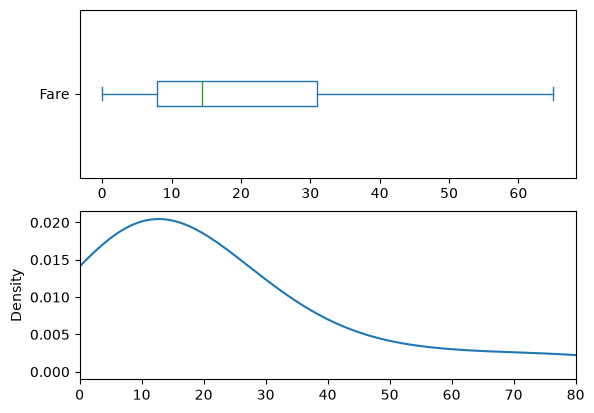

In [12]:
figure, (ax1, ax2) = pyplot.subplots(2, 1)

c4.plot.box(vert=False, showfliers=False, ax=ax1)
c4.plot.density(ax=ax2)

pyplot.xlim((0, 80))

In [13]:
c4.sort_values()

271      0.0000
597      0.0000
302      0.0000
633      0.0000
277      0.0000
         ...   
438    263.0000
341    263.0000
737    512.3292
258    512.3292
679    512.3292
Name: Fare, Length: 891, dtype: float64

In [17]:
p = numpy.linspace(0, 100, 891)

c4_percentil = pandas.DataFrame({
    "Percentil": p,
    "Fare": c4.sort_values(),
}).reset_index().drop("index", axis=1)

c4_percentil

,Percentil,Fare
0,0.000000,0.0000
1,0.112360,0.0000
2,0.224719,0.0000
3,0.337079,0.0000
4,0.449438,0.0000
...,...,...
886,99.550562,263.0000
887,99.662921,263.0000
888,99.775281,512.3292
889,99.887640,512.3292


<Axes: >

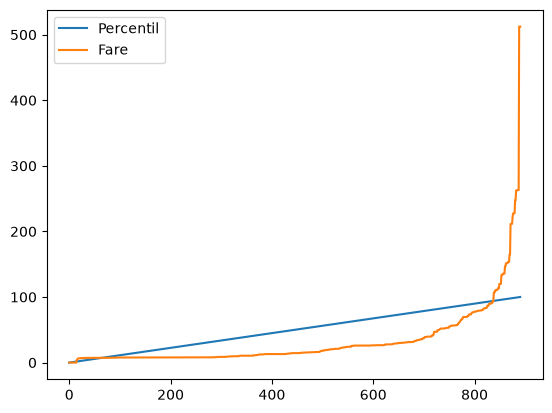

In [18]:
c4_percentil.plot.line()

<Axes: xlabel='Percentil', ylabel='Fare'>

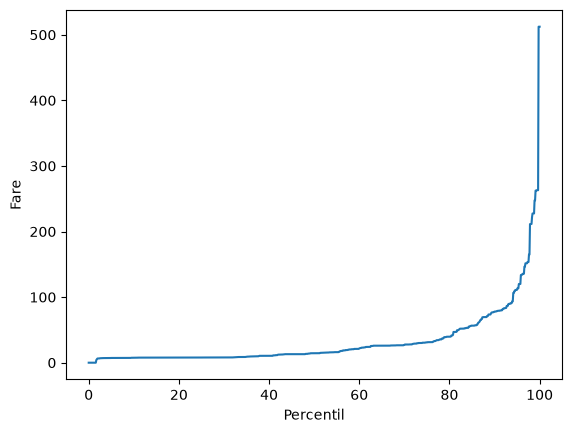

In [19]:
seaborn.lineplot(x=c4_percentil["Percentil"], y=c4_percentil["Fare"])

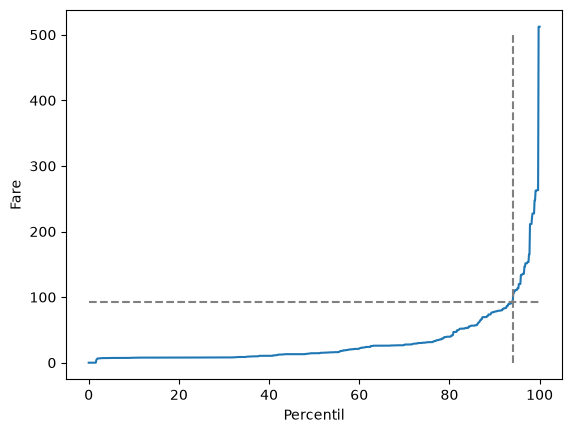

In [22]:
seaborn.lineplot(x=c4_percentil["Percentil"], y=c4_percentil["Fare"])
pyplot.vlines(94, 0, 500, color="gray", linestyle="--") # Corte atípico (percitil %)
pyplot.hlines(92, 0, 100, color="gray", linestyle="--") # Corte atípico (valor)

# Hipótesis visual: 94% de los pasajeros pagaron menos de 92 libras

In [23]:
c4[c4 <= 113].count(), c4.count(), 100 * c4[c4 <= 113].count() / c4.count()

(np.int64(846), np.int64(891), np.float64(94.94949494949495))

In [25]:
c4_percentil["P"] = c4_percentil["Percentil"].astype(int)

c4_percentil.groupby("P").mean().tail(11)

,Percentil,Fare
P,,
90,90.449438,78.500922
91,91.460674,80.153233
92,92.471910,84.232856
93,93.483146,90.429644
94,94.494382,107.520356
95,95.505618,120.791667
96,96.516854,141.337944
97,97.528090,168.432878
98,98.539326,227.750922


In [26]:
p = numpy.linspace(0, 100, 891) # 891 observaciones distribuidas en 100%

c4_percentil = pandas.DataFrame({
    "Percentil": p,
    "Fare": c4.sort_values(),
}).reset_index().drop("index", axis=1)

c4_percentil 

,Percentil,Fare
0,0.000000,0.0000
1,0.112360,0.0000
2,0.224719,0.0000
3,0.337079,0.0000
4,0.449438,0.0000
...,...,...
886,99.550562,263.0000
887,99.662921,263.0000
888,99.775281,512.3292
889,99.887640,512.3292


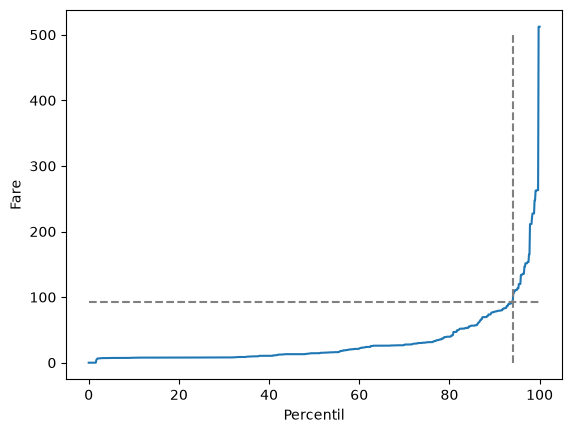

In [27]:
seaborn.lineplot(x=c4_percentil["Percentil"], y=c4_percentil["Fare"])
pyplot.vlines(94, 0, 500, color="gray", linestyle="--") # Corte atípico (percitil %)
pyplot.hlines(92, 0, 100, color="gray", linestyle="--") # Corte atípico (valor)

# Hipótesis visual: 94% de los pasajeros pagaron menos de 92 libras

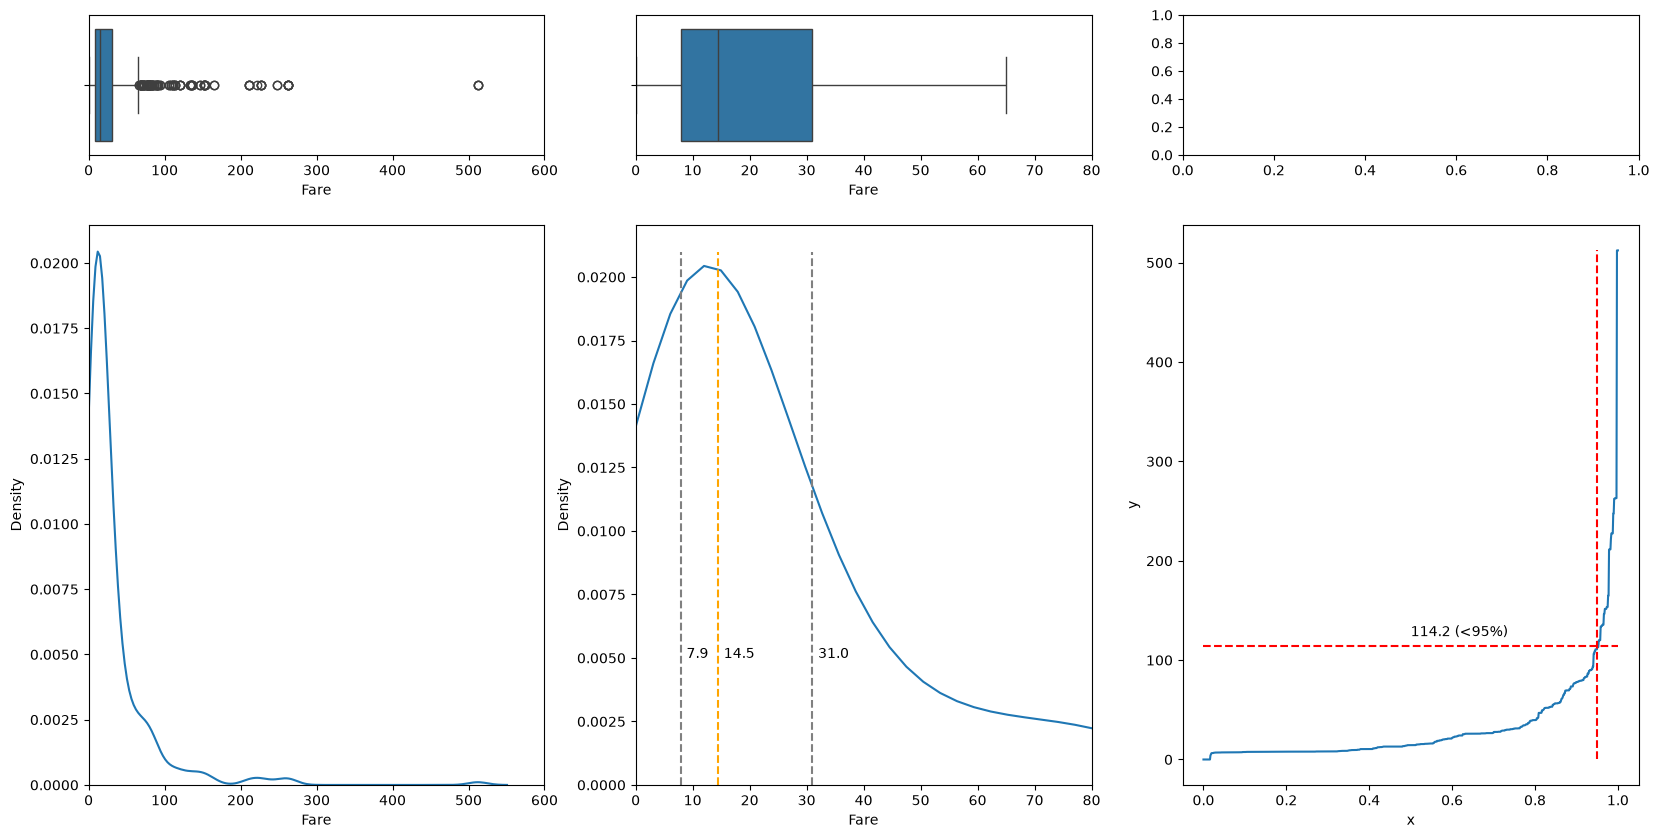

In [30]:
figure, ax = pyplot.subplots(2, 3, height_ratios=(1, 4), figsize=(20, 10))

seaborn.boxplot(x=c4, ax=ax[0, 0])
ax[0, 0].set_xlim((0, 600))
seaborn.boxplot(x=c4, showfliers=False, ax=ax[0, 1])
ax[0, 1].set_xlim((0, 80))

seaborn.kdeplot(x=c4, ax=ax[1, 0])
ax[1, 0].set_xlim((0, 600))
seaborn.kdeplot(x=c4, ax=ax[1, 1])
ax[1, 1].set_xlim((0, 80))
q1 = c4.quantile(0.25)
q2 = c4.quantile(0.50)
q3 = c4.quantile(0.75)
ax[1, 1].vlines(q1, 0, 0.021, color="gray", linestyle="--")
ax[1, 1].vlines(q2, 0, 0.021, color="orange", linestyle="--")
ax[1, 1].vlines(q3, 0, 0.021, color="gray", linestyle="--")
ax[1, 1].text(q1 + 1, 0.005, f"{q1:.1f}")
ax[1, 1].text(q2 + 1, 0.005, f"{q2:.1f}")
ax[1, 1].text(q3 + 1, 0.005, f"{q3:.1f}")

curva = pandas.DataFrame({
    "x": numpy.linspace(0, 1, c4.count()),
    "y": c4.sort_values().values,
})

seaborn.lineplot(x=curva["x"], y=curva["y"], ax=ax[1, 2])
ax[1, 2].vlines(0.95, c4.min(), c4.max(), color="red", linestyle="--")
y_95 = curva[(curva["x"] > 0.94) & (curva["x"] < 0.96)].mean()["y"]
ax[1, 2].hlines(y_95, 0, 1, color="red", linestyle="--")
ax[1, 2].text(0.5, y_95 + 10, f"{y_95:.1f} (<95%)")

figure.savefig("Reporte M303.1.png", dpi=300)
pyplot.show()

  0%:   0.00 [  0.00%]
  5%:   7.22 [  4.50%]
 10%:   7.55 [  2.65%]
 15%:   7.75 [  1.34%]
 20%:   7.85 [  0.72%]
 25%:   7.91 [  1.76%]
 30%:   8.05 [ 11.80%]
 35%:   9.00 [ 16.67%]
 40%:  10.50 [ 23.81%]
 45%:  13.00 [ 11.19%]
 50%:  14.45 [ 11.39%]
 55%:  16.10 [ 34.65%]
 60%:  21.68 [ 19.93%]
 65%:  26.00 [  3.85%]
 70%:  27.00 [ 14.81%]
 75%:  31.00 [ 28.02%]
 80%:  39.69 [ 42.35%]
 85%:  56.50 [ 37.99%]
 90%:  77.96 [ 43.77%]
 95%: 112.08 [357.11%]
100%: 512.33 [  0.00%]


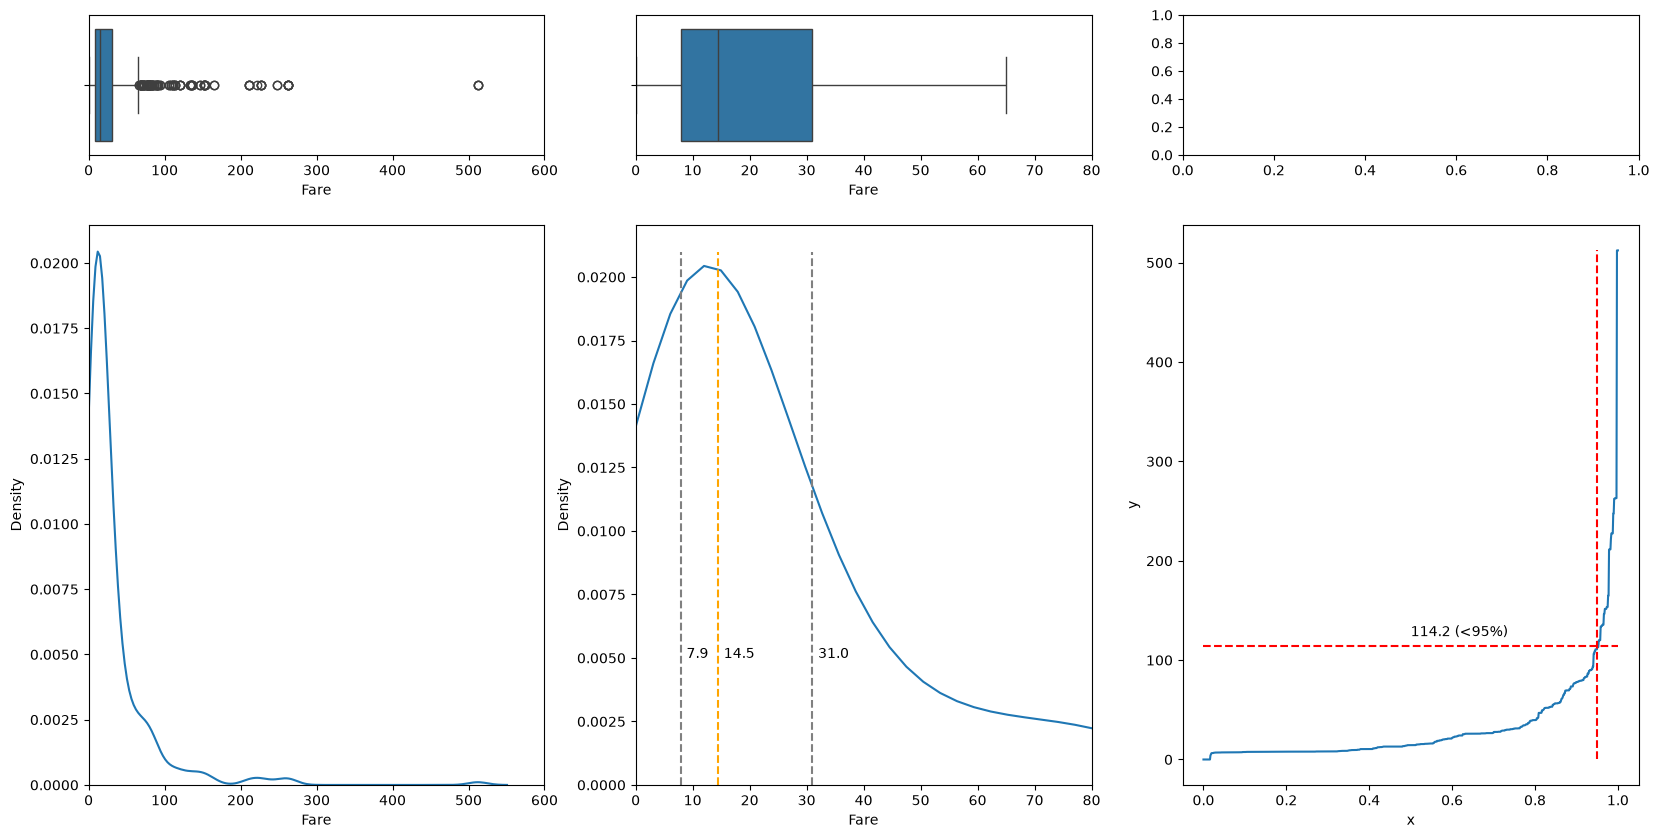

In [31]:
figure, ax = pyplot.subplots(2, 3, height_ratios=(1, 4), figsize=(20, 10))

seaborn.boxplot(x=c4, ax=ax[0, 0])
ax[0, 0].set_xlim((0, 600))
seaborn.boxplot(x=c4, showfliers=False, ax=ax[0, 1])
ax[0, 1].set_xlim((0, 80))

seaborn.kdeplot(x=c4, ax=ax[1, 0])
ax[1, 0].set_xlim((0, 600))
seaborn.kdeplot(x=c4, ax=ax[1, 1])
ax[1, 1].set_xlim((0, 80))
q1 = c4.quantile(0.25)
q2 = c4.quantile(0.50)
q3 = c4.quantile(0.75)
ax[1, 1].vlines(q1, 0, 0.021, color="gray", linestyle="--")
ax[1, 1].vlines(q2, 0, 0.021, color="orange", linestyle="--")
ax[1, 1].vlines(q3, 0, 0.021, color="gray", linestyle="--")
ax[1, 1].text(q1 + 1, 0.005, f"{q1:.1f}")
ax[1, 1].text(q2 + 1, 0.005, f"{q2:.1f}")
ax[1, 1].text(q3 + 1, 0.005, f"{q3:.1f}")

curva = pandas.DataFrame({
    "x": numpy.linspace(0, 1, c4.count()),
    "y": c4.sort_values().values,
})

seaborn.lineplot(x=curva["x"], y=curva["y"], ax=ax[1, 2])
ax[1, 2].vlines(0.95, c4.min(), c4.max(), color="red", linestyle="--")
y_95 = curva[(curva["x"] > 0.94) & (curva["x"] < 0.96)].mean()["y"]
ax[1, 2].hlines(y_95, 0, 1, color="red", linestyle="--")
ax[1, 2].text(0.5, y_95 + 10, f"{y_95:.1f} (<95%)")

for i in range(0, 21):
    a = 0.05 * i
    q = c4.quantile(a)
    inflacion = 0
    if a > 0 and a < 20:
        qs = c4.quantile(max(min(a + 0.05, 1), 0))
        inflacion = (qs - q) / q
    print(f"{100 * a:3.0f}%: {q:6.2f} [{100 * inflacion:6.2f}%]")

figure.savefig("Reporte M303.1.png", dpi=300)
pyplot.show()

In [33]:
def visualizar_continuo(serie, corte=0.95, dmax = 0.021, cuantiles=True, nombre="reporte.png"):
    figure, ax = pyplot.subplots(2, 3, height_ratios=(1, 4), figsize=(20, 10))

    q1 = serie.quantile(0.25)
    q2 = serie.quantile(0.50)
    q3 = serie.quantile(0.75)
    IQR = q3 - q1
    minrel = max(q1 - 1.5 * IQR, serie.min())
    maxrel = min(q3 + 1.5 * IQR, serie.max())

    if minrel == maxrel:
        maxrel += 1
    
    seaborn.boxplot(x=serie, ax=ax[0, 0])
    ax[0, 0].set_xlim((serie.min(), serie.max()))
    seaborn.boxplot(x=serie, showfliers=False, ax=ax[0, 1])
    ax[0, 1].set_xlim((minrel, maxrel))
    
    seaborn.kdeplot(x=serie, ax=ax[1, 0])
    ax[1, 0].set_xlim((serie.min(), serie.max()))
    seaborn.kdeplot(x=serie, ax=ax[1, 1])
    ax[1, 1].set_xlim((minrel, maxrel))
    
    ax[1, 1].vlines(q1, 0, dmax, color="gray", linestyle="--")
    ax[1, 1].vlines(q2, 0, dmax, color="orange", linestyle="--")
    ax[1, 1].vlines(q3, 0, dmax, color="gray", linestyle="--")
    ax[1, 1].text(q1 + 1, dmax / 4, f"{q1:.1f}")
    ax[1, 1].text(q2 + 1, dmax / 4, f"{q2:.1f}")
    ax[1, 1].text(q3 + 1, dmax / 4, f"{q3:.1f}")
    
    curva = pandas.DataFrame({
        "x": numpy.linspace(0, 1, serie.size),
        "y": serie.sort_values().values,
    })
    
    seaborn.lineplot(x=curva["x"], y=curva["y"], ax=ax[1, 2])
    ax[1, 2].vlines(corte, serie.min(), serie.max(), color="red", linestyle="--")
    y_corte = curva[(curva["x"] > (corte - 0.01)) & (curva["x"] < (corte + 0.01))].mean()["y"]
    ax[1, 2].hlines(y_corte, 0, 1, color="red", linestyle="--")
    ax[1, 2].text(0.5, y_corte + 10, f"{y_corte:.1f} (<{100 * corte:.0f}%)")

    if cuantiles:
        for i in range(0, 21):
            a = 0.05 * i
            q = serie.quantile(a)
            inflacion = 0
            if a > 0 and a < 20:
                qs = serie.quantile(max(min(a + 0.05, 1), 0))
                inflacion = (qs - q) / q
            print(f"{100 * a:3.0f}%: {q:6.2f} [{100 * inflacion:6.2f}%]")
    
    figure.savefig(nombre, dpi=300)
    pyplot.show()

  0%:   0.00 [  0.00%]
  5%:   7.22 [  4.50%]
 10%:   7.55 [  2.65%]
 15%:   7.75 [  1.34%]
 20%:   7.85 [  0.72%]
 25%:   7.91 [  1.76%]
 30%:   8.05 [ 11.80%]
 35%:   9.00 [ 16.67%]
 40%:  10.50 [ 23.81%]
 45%:  13.00 [ 11.19%]
 50%:  14.45 [ 11.39%]
 55%:  16.10 [ 34.65%]
 60%:  21.68 [ 19.93%]
 65%:  26.00 [  3.85%]
 70%:  27.00 [ 14.81%]
 75%:  31.00 [ 28.02%]
 80%:  39.69 [ 42.35%]
 85%:  56.50 [ 37.99%]
 90%:  77.96 [ 43.77%]
 95%: 112.08 [357.11%]
100%: 512.33 [  0.00%]


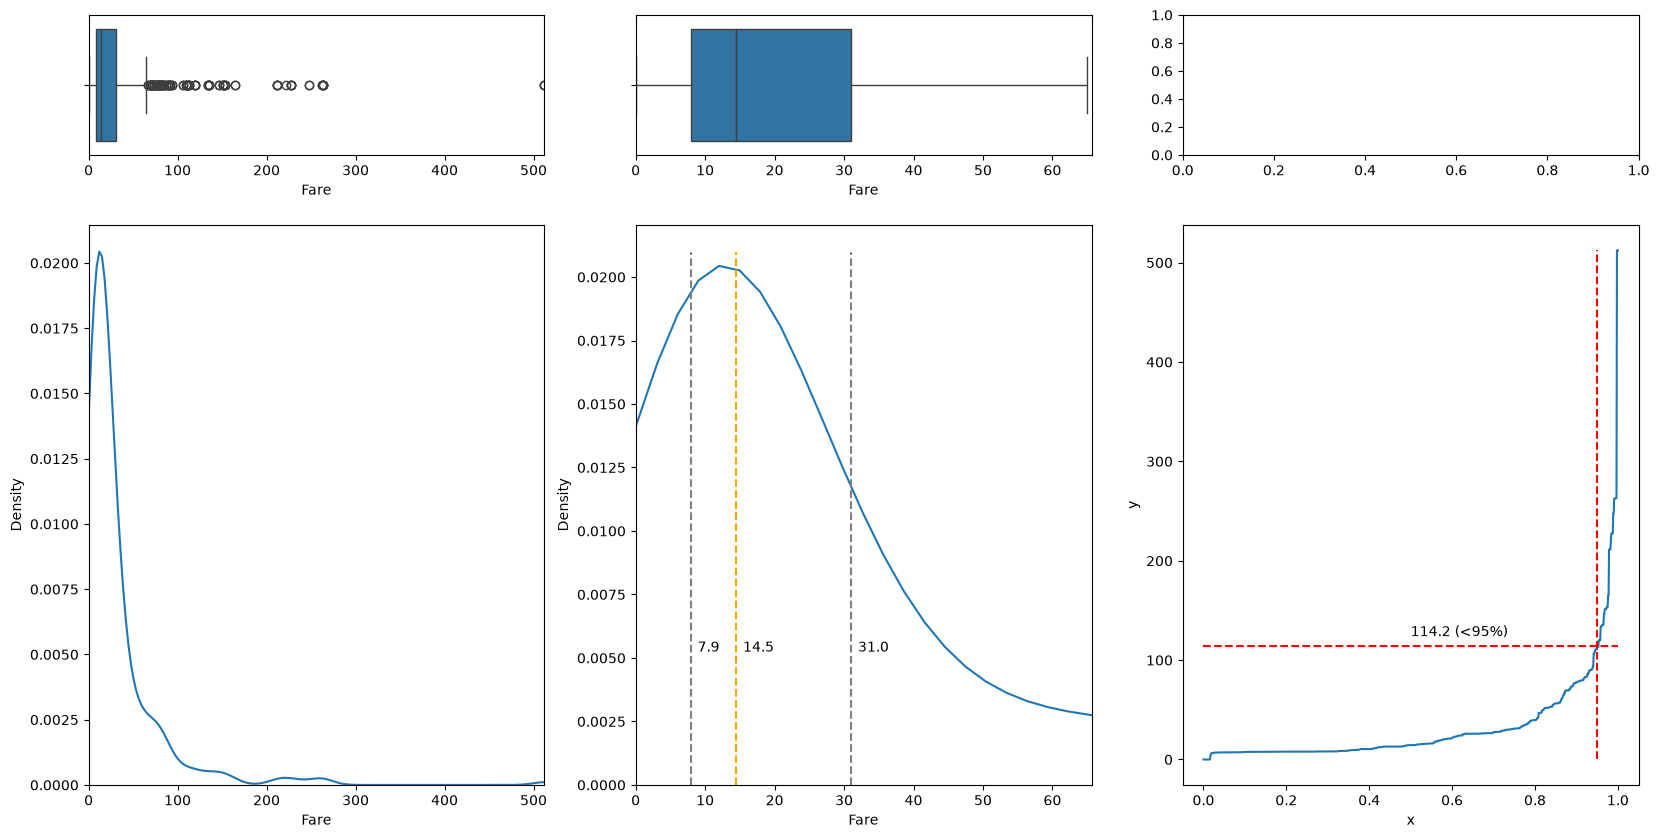

In [34]:
visualizar_continuo(c4, 0.95, 0.021, True, "Reporte M303.1.png")

  0%:   0.42 [  0.00%]
  5%:   4.00 [250.00%]
 10%:  14.00 [ 21.43%]
 15%:  17.00 [ 11.76%]
 20%:  19.00 [  5.92%]
 25%:  20.12 [  9.32%]
 30%:  22.00 [  9.09%]
 35%:  24.00 [  4.17%]
 40%:  25.00 [  8.00%]
 45%:  27.00 [  3.70%]
 50%:  28.00 [  7.14%]
 55%:  30.00 [  6.00%]
 60%:  31.80 [  6.92%]
 65%:  34.00 [  5.88%]
 70%:  36.00 [  5.56%]
 75%:  38.00 [  7.89%]
 80%:  41.00 [  9.76%]
 85%:  45.00 [ 11.11%]
 90%:  50.00 [ 12.00%]
 95%:  56.00 [ 42.86%]
100%:  80.00 [  0.00%]


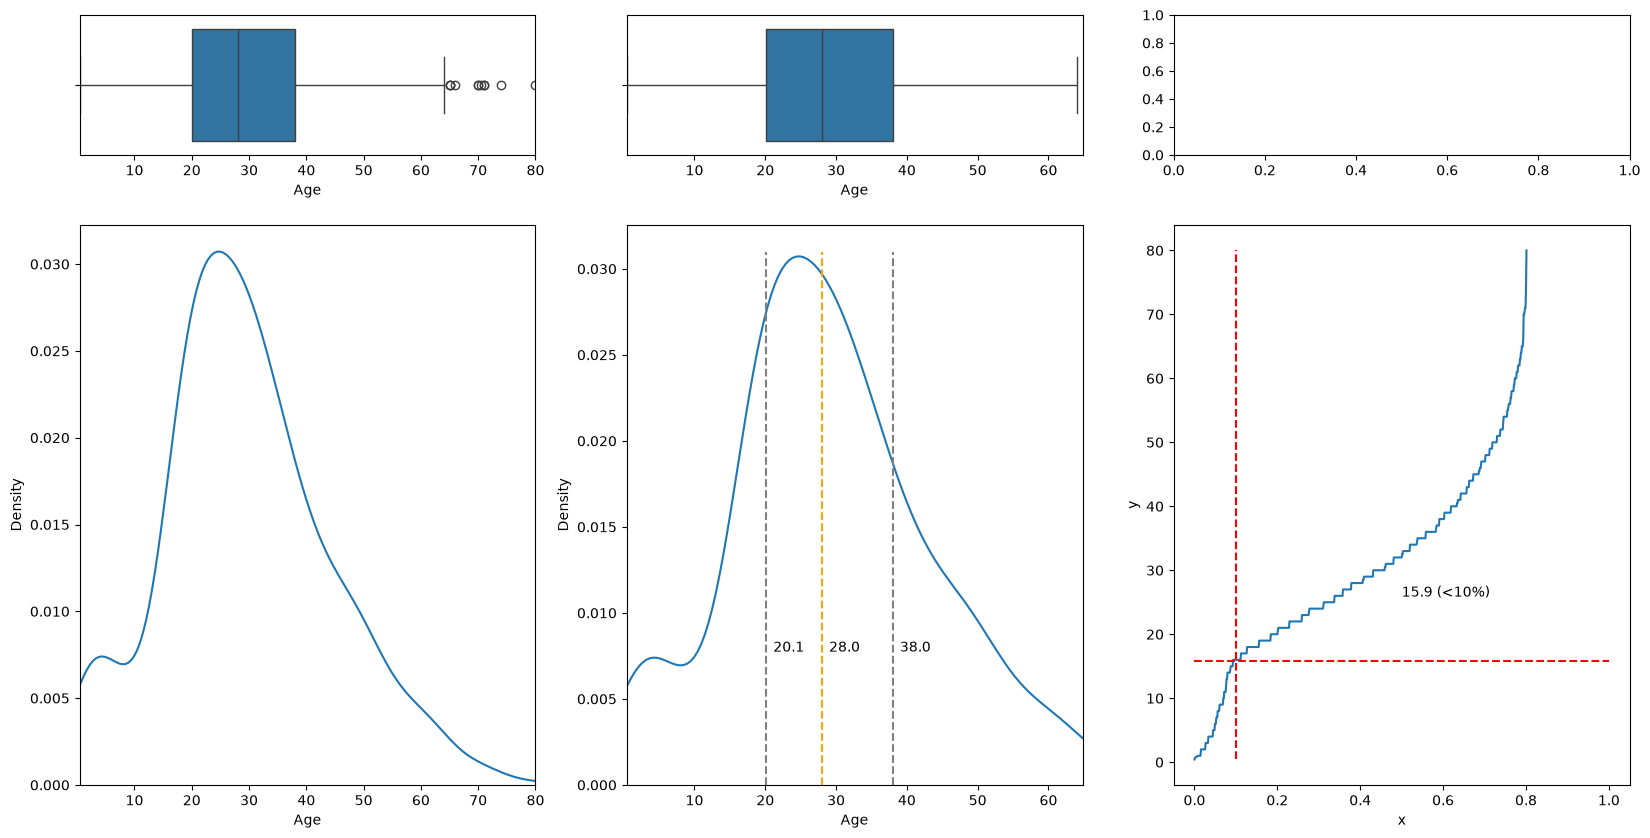

In [35]:
visualizar_continuo(c7, 0.10, 0.031, True, "Reporte M303.2.png")

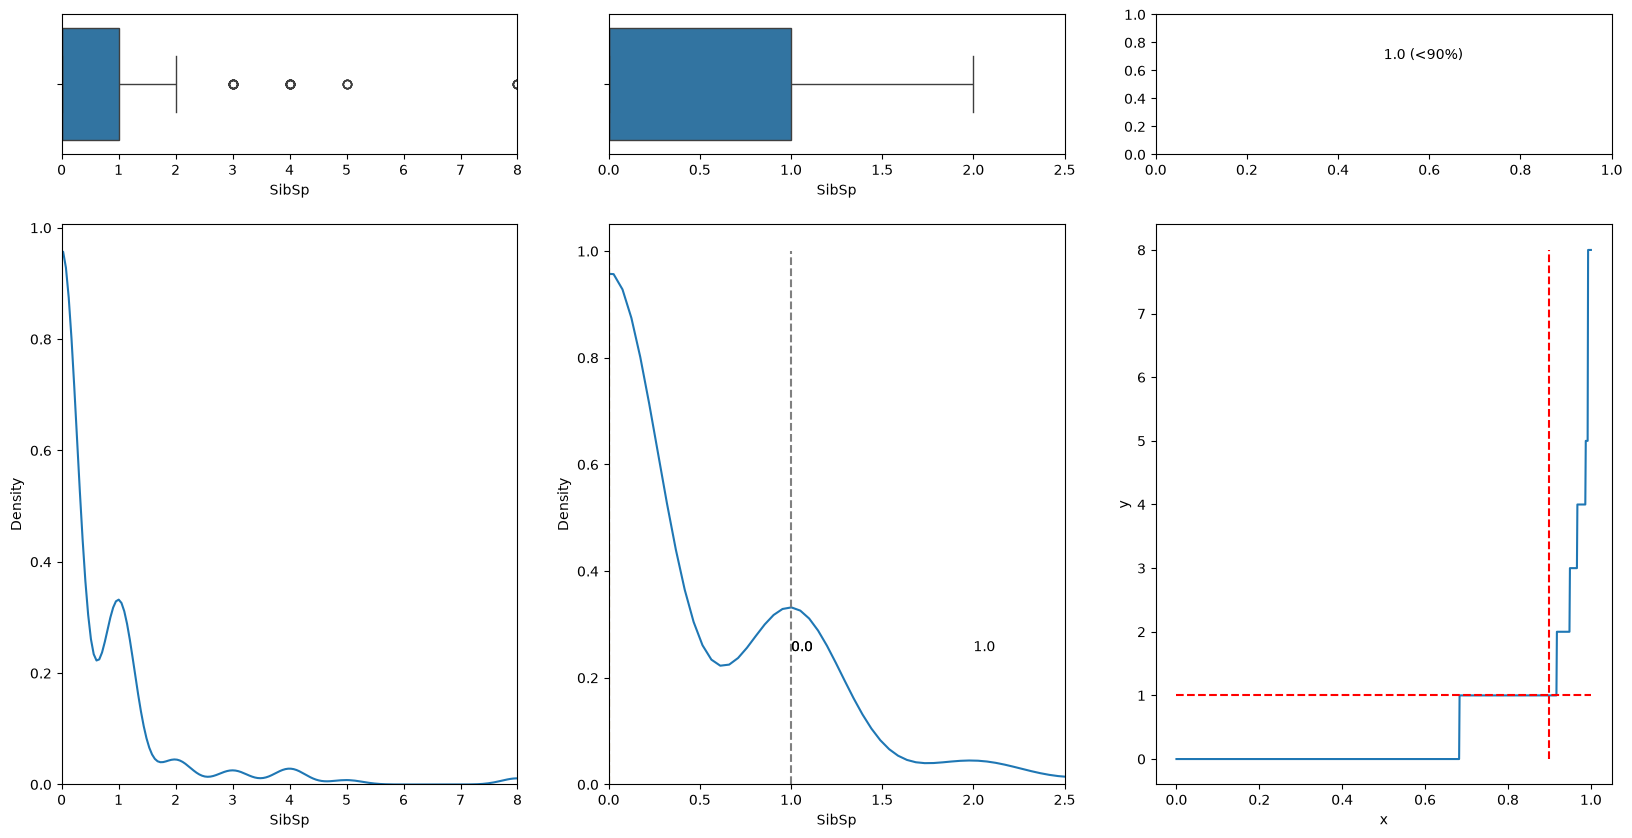

In [36]:
visualizar_continuo(c8, 0.90, 1, False, "Reporte M303.3.png")

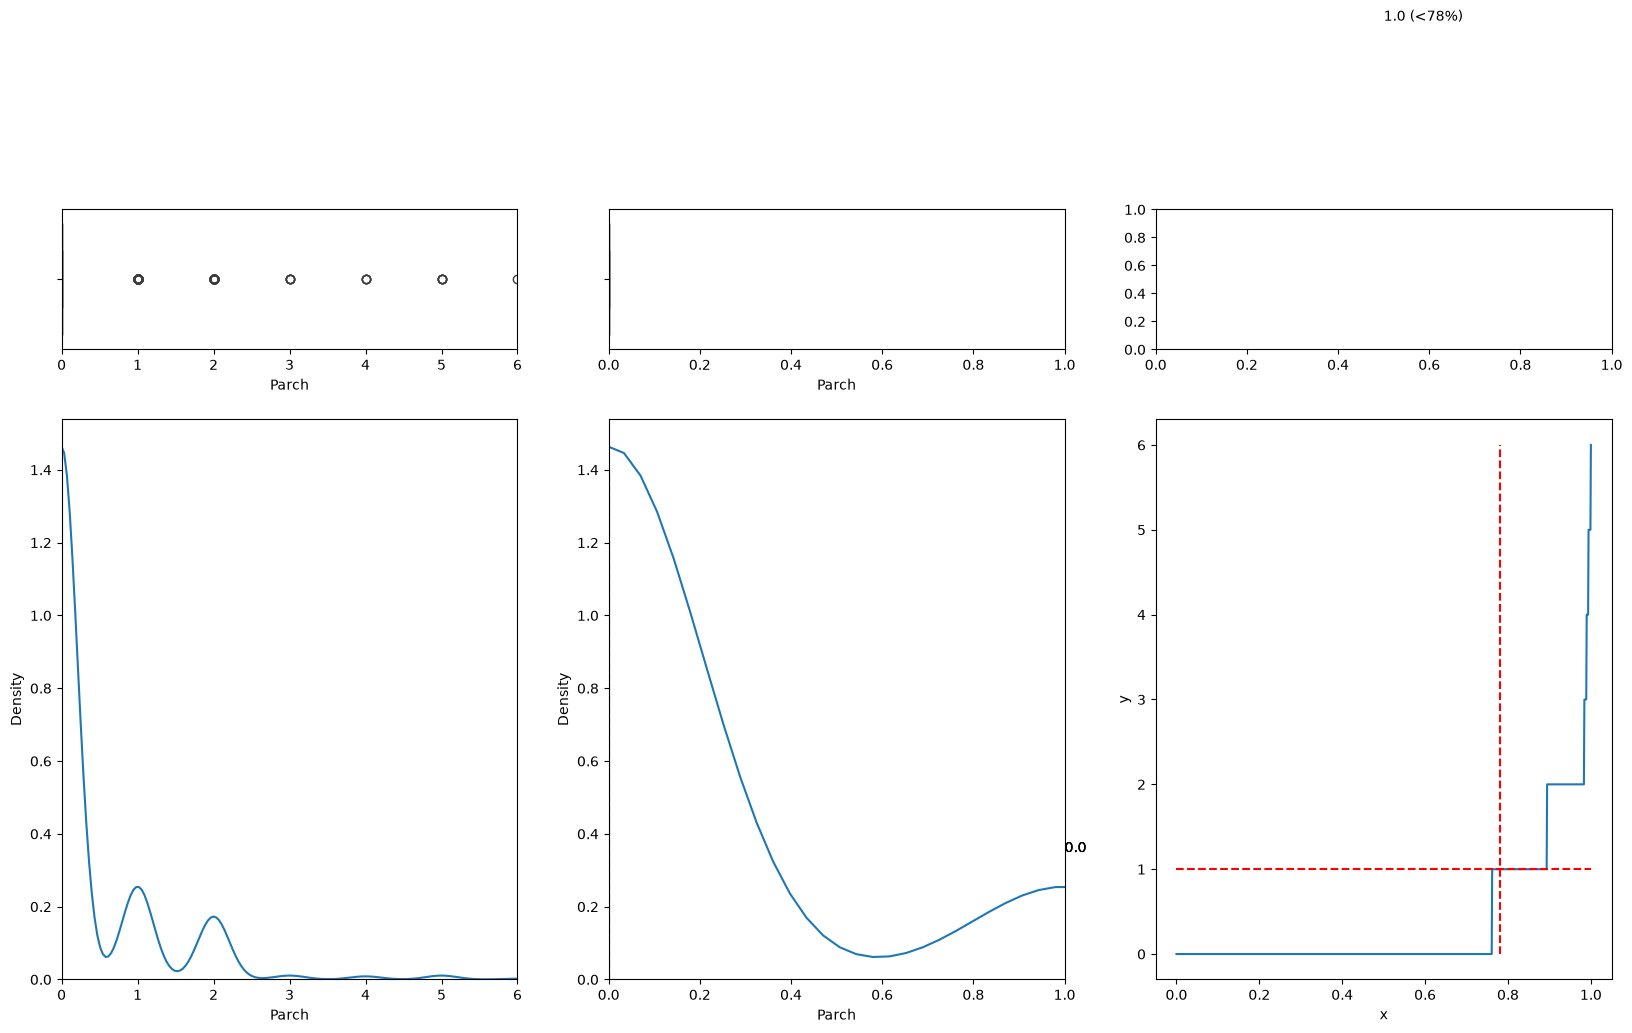

In [37]:
visualizar_continuo(c9, 0.78, 1.4, False, "Reporte M303.4.png")

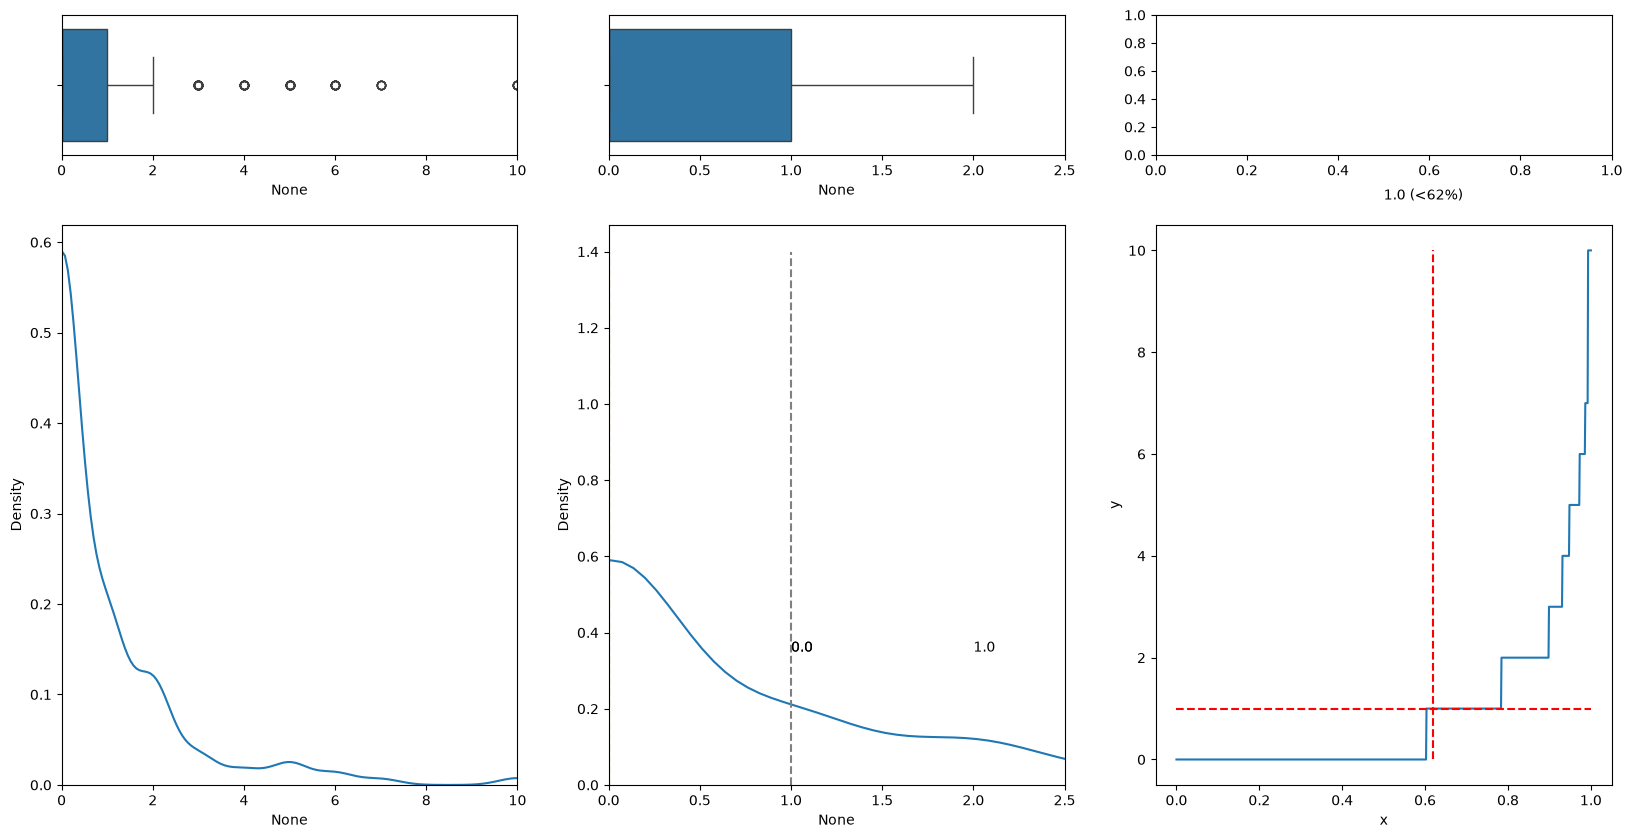

In [38]:
c10 = c8 + c9 # Suma de famila (hermanos/cónyugues) + (padres/hijos)

visualizar_continuo(c10, 0.62, 1.4, False, "Reporte M303.5.png")

In [40]:
def familia_cat(familia):
    if familia == 0:
        return "alone"
    elif familia == 1:
        return "couple"
    elif familia <= 3:
        return "small"
    else:
        return "big"

c11 = c10.apply(familia_cat)

c11.name = "Family"

c11.value_counts()

Family
alone     537
couple    161
small     131
big        62
Name: count, dtype: int64

In [41]:
c11.value_counts(normalize=True)

Family
alone     0.602694
couple    0.180696
small     0.147026
big       0.069585
Name: proportion, dtype: float64

In [ ]:
2. Análisis Individual para Características Discretas

In [42]:
# c1, c2, c3, c5, c6, c11
pandas.DataFrame([c1, c2, c3, c5, c6, c11]).T

,Survived,Sex,Pclass,Cabin,Embarked,Family
0,no,male,3rd,no,southampton,couple
1,yes,female,1st,yes,cherbug,couple
2,yes,female,3rd,no,southampton,alone
3,yes,female,1st,yes,southampton,couple
4,no,male,3rd,no,southampton,alone
...,...,...,...,...,...,...
886,no,male,2nd,no,southampton,alone
887,yes,female,1st,yes,southampton,alone
888,no,female,3rd,no,southampton,small
889,yes,male,1st,yes,cherbug,alone


In [43]:
pandas.concat([
    c1.value_counts(),
    (c1.value_counts(normalize=True) * 100).round(1),
], axis=1)

,count,proportion
Survived,,
no,549,61.6
yes,342,38.4


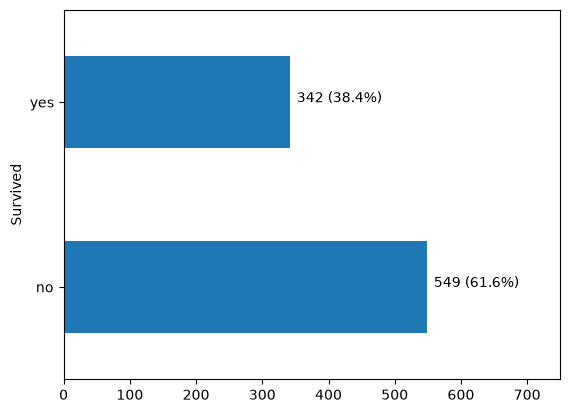

In [44]:
c1.value_counts().plot.barh()
soporte_no = c1.value_counts().loc["no"]
proporcion_no = c1.value_counts(normalize=True).loc["no"]
soporte_yes = c1.value_counts().loc["yes"]
proporcion_yes = c1.value_counts(normalize=True).loc["yes"]
pyplot.text(c1.value_counts().loc["no"] + 10, 0, f"{soporte_no} ({100 * proporcion_no:.1f}%)")
pyplot.text(c1.value_counts().loc["yes"] + 10, 1, f"{soporte_yes} ({100 * proporcion_yes:.1f}%)")
pyplot.xlim((0, c1.value_counts().max() + 200))

pyplot.savefig("Reporte M303.5.png", dpi=300)

pyplot.show()

In [46]:
def visualizar_discreto(serie, delta=200, nombre="reporte.png"):
    print(
        pandas.concat([
            serie.value_counts(),
            (serie.value_counts(normalize=True) * 100).round(1),
        ], axis=1)
    )
    
    serie.value_counts().plot.barh()
    pyplot.xlim((0, serie.value_counts().max() + delta))
    i = 0
    for clase in serie.unique():
        soporte = serie.value_counts().loc[clase]
        proporcion = serie.value_counts(normalize=True).loc[clase]
        pyplot.text(serie.value_counts().loc[clase] + 10, i, f"{soporte_no} ({100 * proporcion_n:.1f}%)")
        i += 1
    
    pyplot.savefig(nombre, dpi=300)
    
    pyplot.show()

          count  proportion
Survived                   
no          549        61.6
yes         342        38.4


NameError: name 'proporcion_n' is not defined

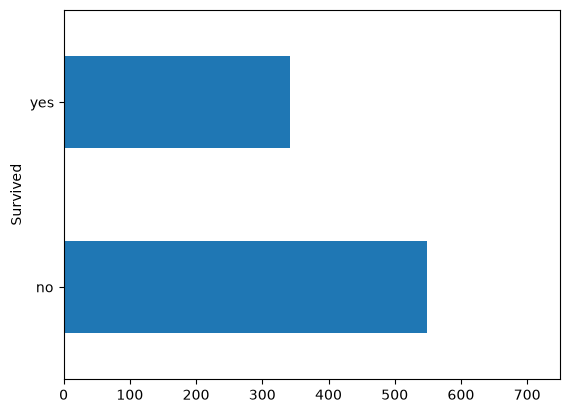

In [52]:
visualizar_discreto(c1, 200, "Reporte M303.5.png")

        count  proportion
Sex                      
male      577        64.8
female    314        35.2


NameError: name 'proporcion_n' is not defined

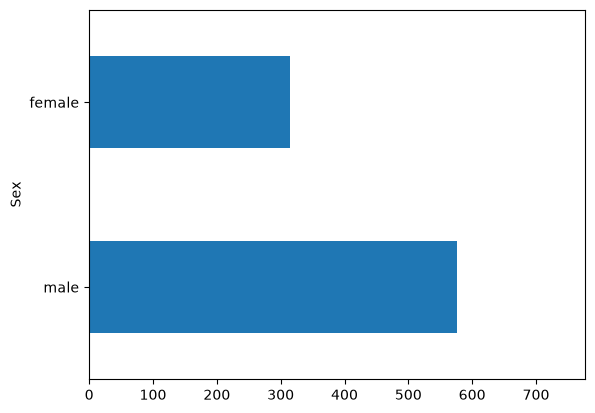

In [50]:
visualizar_discreto(c2, 200, "Reporte M3036.png")

       count  proportion
Cabin                   
no       687        77.1
yes      204        22.9


NameError: name 'proporcion_n' is not defined

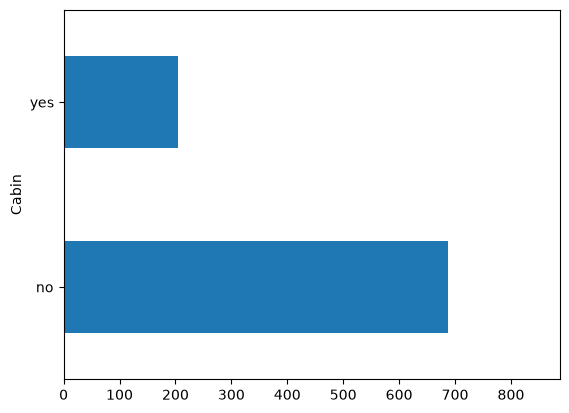

In [54]:
visualizar_discreto(c5, 200, "Reporte M303.6.png")

       count  proportion
Cabin                   
no       687        77.1
yes      204        22.9


NameError: name 'proporcion_n' is not defined

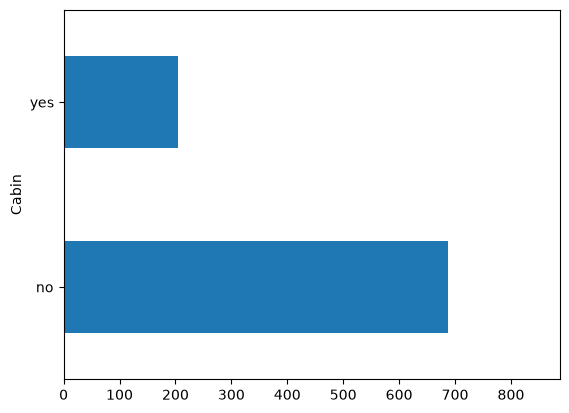

In [55]:
visualizar_discreto(c5, 200, "Reporte M303.7.png")

In [ ]:
visualizar_discreto(c5, 200, "Reporte M303.8.png")

             count  proportion
Embarked                      
southampton    644        72.4
cherbug        168        18.9
queenstown      77         8.7


NameError: name 'proporcion_n' is not defined

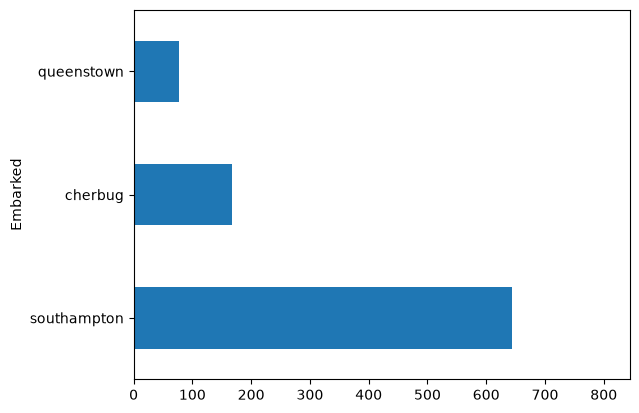

In [56]:
visualizar_discreto(c6, 200, "Reporte M303.9.png")

        count  proportion
Family                   
alone     537        60.3
couple    161        18.1
small     131        14.7
big        62         7.0


NameError: name 'proporcion_n' is not defined

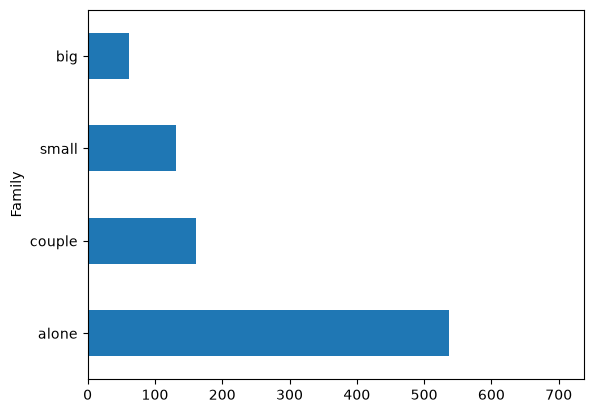

In [57]:
visualizar_discreto(c11, 200, "Reporte M303.10.png")

3. Selección de la Respuesta

Problema de Regresión -> Explicar una respuesta continua (abierto)

Que las características expliquen el continuo de la respuesta (modelo lineal)

Problema de Clasificación -> Explicar una respuesta discreta (cerrado)

Que las características expliquen el cada valor discreto de la respuesta (logístico/árbol de decisión)

Ejemplo 1: La respuesta es continua (la tarifa)

<Axes: xlabel='Age', ylabel='Fare'>

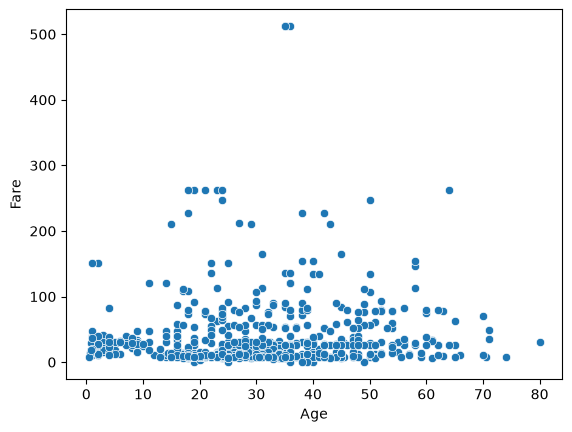

In [58]:
seaborn.scatterplot(x=c7, y=c4)

<Axes: xlabel='Pclass', ylabel='Fare'>

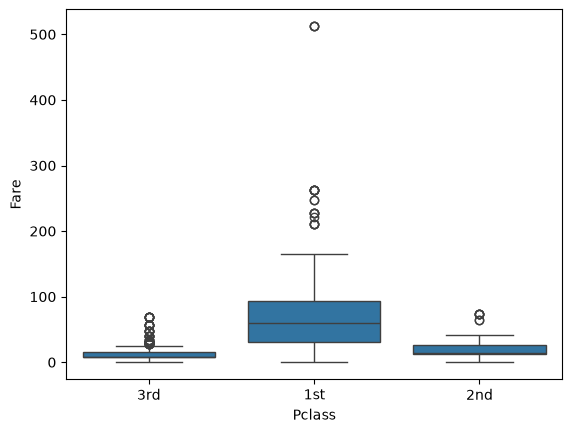

In [59]:
seaborn.boxplot(x=c3, y=c4) # La clase del pasajero explica las tarifas

<Axes: xlabel='Pclass', ylabel='Fare'>

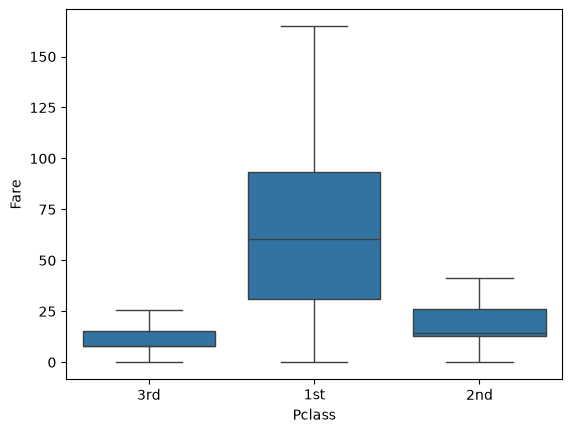

In [60]:
seaborn.boxplot(x=c3, y=c4, showfliers=False)

<Axes: xlabel='Fare', ylabel='Density'>

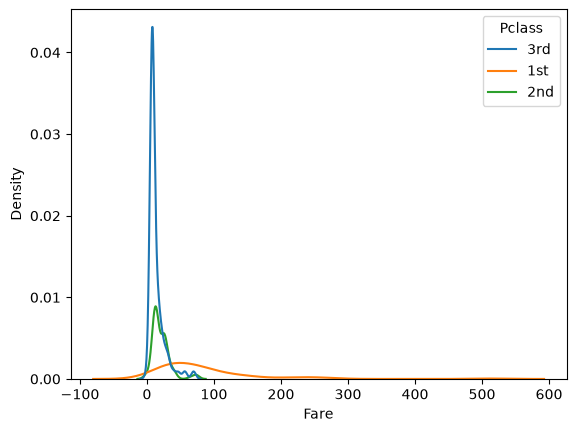

In [61]:
fliers = c4[(c4 >= c4.quantile(0.25)) & (c4 <= c4.quantile(0.25))]

seaborn.kdeplot(x=c4, hue=c3)

<Axes: xlabel='Fare', ylabel='Density'>

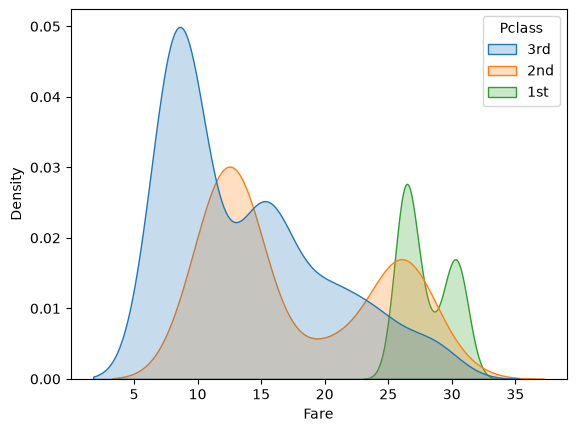

In [62]:
fliers = (c4 >= c4.quantile(0.25)) & (c4 <= c4.quantile(0.75))

seaborn.kdeplot(x=c4[fliers], hue=c3[fliers], fill=True)

<Axes: xlabel='Fare', ylabel='Density'>

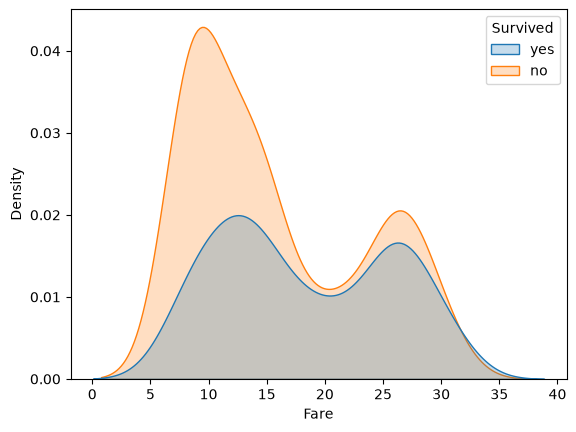

In [63]:
fliers = (c4 >= c4.quantile(0.25)) & (c4 <= c4.quantile(0.75))

seaborn.kdeplot(x=c4[fliers], hue=c1[fliers], fill=True)

<Axes: ylabel='Fare'>

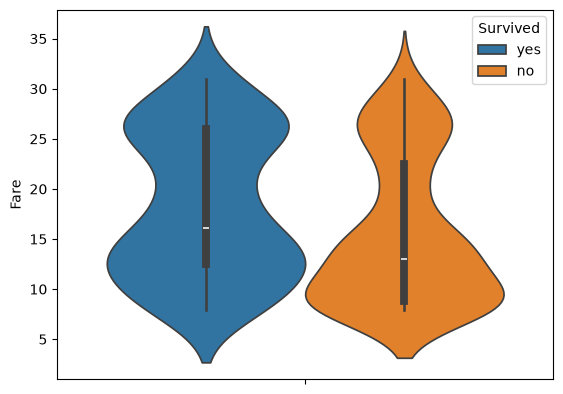

In [66]:
fliers = (c4 >= c4.quantile(0.25)) & (c4 <= c4.quantile(0.75))

seaborn.violinplot(y=c4[fliers], hue=c1[fliers], fill=True)

In [ ]:
4. Discretización

In [ ]:
5. Cuantización

In [ ]:
5. Cuantización